# Bio-Sniff QAOA Synthetic Architecture Benchmark

**Run cells from top to bottom.** Cell 1 installs dependencies; after installation, restart the runtime if Colab requests it, then run the remaining cells in order. This benchmark uses synthetic placement scenarios, not measured field data. The results CSV, configuration file, and multi-start optimizer summary are generated from the current run in the final export cell. The benchmark uses five optimizer starting seeds for each problem size. No manually typed benchmark results are used.


In [1]:
%pip install -q --upgrade \
    "numpy==2.2.6" \
    "pandas==2.2.3" \
    "scipy>=1.14,<2.0" \
    "qiskit==2.3.0" \
    "qiskit-aer==0.17.2" \
    "networkx>=3.2,<4.0" \
    "matplotlib>=3.8,<4.0" \
    "seaborn>=0.13,<1.0" \
    "plotly>=5.20,<7.0" \
    "pylatexenc" \
    "scikit-learn>=1.4,<2.0"


print("Installation step complete. Restart the runtime before continuing.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2

In [1]:
import numpy, pandas, scipy, qiskit, qiskit_aer
import networkx, matplotlib, seaborn, sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("All core imports successful.")

NumPy: 2.2.6
Pandas: 2.2.3
SciPy: 1.18.1
Qiskit: 2.3.0
Qiskit Aer: 0.17.2
All core imports successful.


In [2]:
import itertools
import time
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

# ============================================================
# 1. REPRODUCIBILITY AND BENCHMARK SETTINGS
# ============================================================

SEED = 42
SHOTS = 4096
QAOA_P = 1
K_SELECTED = 3
PENALTY = 3.0
MAXITER = 60

BASIS_GATES = ["rz", "sx", "x", "cx"]

np.random.seed(SEED)

# ============================================================
# 2. PROCESSOR COUPLING MAPS
# These use the maps in your supplied corrected configuration.
# Each undirected connection is made bidirectional for CX.
# ============================================================

PROCESSOR_A_EDGES = [
    (0, 1), (1, 2), (1, 3), (3, 4)
]

PROCESSOR_B_EDGES = [
    (0, 1), (1, 2), (1, 6), (2, 3),
    (2, 6), (2, 5), (3, 4), (4, 5),
    (5, 6), (6, 7), (6, 8), (8, 0)
]

def bidirectional_edges(edges):
    return sorted(set(
        list(edges) + [(v, u) for u, v in edges]
    ))

COUPLING_A = bidirectional_edges(PROCESSOR_A_EDGES)
COUPLING_B = bidirectional_edges(PROCESSOR_B_EDGES)

# Official noise rates listed in the uploaded Master Guide.
P_1Q = 0.001
P_CX = 0.005
P_READOUT = 0.01

def make_noise_model():
    noise = NoiseModel()

    # Apply the same single-qubit depolarizing rate to the
    # benchmark's one-qubit basis gates.
    error_1q = depolarizing_error(P_1Q, 1)
    noise.add_all_qubit_quantum_error(
        error_1q, ["rz", "sx", "x"]
    )

    error_cx = depolarizing_error(P_CX, 2)
    noise.add_all_qubit_quantum_error(error_cx, ["cx"])

    readout_error = ReadoutError([
        [1 - P_READOUT, P_READOUT],
        [P_READOUT, 1 - P_READOUT]
    ])
    noise.add_all_qubit_readout_error(readout_error)

    return noise

# ============================================================
# 3. REPRODUCIBLE SYNTHETIC BIOSNIFF TEST INSTANCE
# Replace this generator with your actual Case 1 matrices
# when those are available.
# ============================================================

def build_synthetic_problem(seed=SEED, n_scenarios=24):
    rng = np.random.default_rng(seed)

    # Nine candidates arranged in a 3 x 3 field grid.
    coords = np.array([
        [0, 0], [1, 0], [2, 0],
        [0, 1], [1, 1], [2, 1],
        [0, 2], [1, 2], [2, 2]
    ], dtype=float)

    # Synthetic source locations and wind directions.
    sources = rng.uniform(0, 2, size=(n_scenarios, 2))
    wind_angles = rng.uniform(0, 2 * np.pi, size=n_scenarios)

    # Illustrative wind displacement. This is a simulation
    # assumption, not a measured agricultural plume model.
    wind_shift = 0.30 * np.column_stack([
        np.cos(wind_angles), np.sin(wind_angles)
    ])
    shifted_sources = sources + wind_shift

    # Candidate-by-scenario response/coverage scores.
    sigma = 0.70
    coverage = np.zeros((len(coords), n_scenarios))

    for i, point in enumerate(coords):
        distances_sq = np.sum(
            (shifted_sources - point) ** 2, axis=1
        )
        coverage[i] = np.exp(
            -distances_sq / (2 * sigma**2)
        )

    utility = coverage.mean(axis=1)

    # Complementarity: dissimilar response profiles receive
    # higher scores, reducing redundant placement.
    complementarity = np.zeros((9, 9))
    for i in range(9):
        for j in range(9):
            a, b = coverage[i], coverage[j]
            denom = np.linalg.norm(a) * np.linalg.norm(b)
            similarity = np.dot(a, b) / denom if denom else 0.0
            complementarity[i, j] = 1.0 - np.clip(
                similarity, 0.0, 1.0
            )

    # Spacing reward normalized to [0, 1].
    distances = np.linalg.norm(
        coords[:, None, :] - coords[None, :, :], axis=2
    )
    max_distance = distances.max()
    spacing = distances / max_distance if max_distance else distances

    return coords, coverage, utility, complementarity, spacing

COORDS, COVERAGE, UTILITY, COMPLEMENTARITY, SPACING = (
    build_synthetic_problem()
)

# ============================================================
# 4. BUILD THE QUBO
#
# Reward = 60% individual utility
#        + 25% pairwise complementarity
#        + 15% pairwise spacing
#
# Penalty enforces exactly K_SELECTED choices.
# Q stores diagonal and upper-triangle coefficients only.
# ============================================================

def build_qubo(utility, complementarity, spacing,
               k=K_SELECTED, penalty=PENALTY):
    n = len(utility)
    Q = np.zeros((n, n), dtype=float)

    for i in range(n):
        Q[i, i] = (
            -0.60 * utility[i]
            + penalty * (1 - 2 * k)
        )

        for j in range(i + 1, n):
            Q[i, j] = (
                -0.25 * complementarity[i, j]
                -0.15 * spacing[i, j]
                + 2 * penalty
            )

    return Q

def qubo_energy(bitstring, Q):
    # Qiskit bitstrings are ordered q_(n-1) ... q_0.
    bits = np.array(
        [int(c) for c in bitstring[::-1]], dtype=int
    )

    energy = 0.0
    for i in range(len(bits)):
        for j in range(i, len(bits)):
            energy += Q[i, j] * bits[i] * bits[j]

    return float(energy)

def placement_reward(selected, utility, complementarity, spacing):
    # selected contains local candidate indices.
    reward = 0.60 * sum(utility[i] for i in selected)

    for a, i in enumerate(selected):
        for j in selected[a + 1:]:
            reward += 0.25 * complementarity[i, j]
            reward += 0.15 * spacing[i, j]

    return float(reward)

# ============================================================
# 5. QAOA COST CIRCUIT
# Converts the QUBO to Z and ZZ terms.
# ============================================================

def qaoa_circuit(Q, gamma, beta, measure=False):
    n = Q.shape[0]
    qc = QuantumCircuit(n)

    # Initial superposition.
    qc.h(range(n))

    # QUBO: sum_i Qii*x_i + sum_ij Qij*x_i*x_j
    # with x_i = (1 - Z_i)/2.
    h = np.zeros(n)
    J = {}

    for i in range(n):
        h[i] -= Q[i, i] / 2.0

    for i in range(n):
        for j in range(i + 1, n):
            qij = Q[i, j]
            if abs(qij) > 1e-12:
                h[i] -= qij / 4.0
                h[j] -= qij / 4.0
                J[(i, j)] = qij / 4.0

    # Cost unitary.
    for i in range(n):
        if abs(h[i]) > 1e-12:
            qc.rz(2 * gamma * h[i], i)

    for (i, j), coeff in J.items():
        qc.rzz(2 * gamma * coeff, i, j)

    # Standard X mixer.
    for i in range(n):
        qc.rx(2 * beta, i)

    if measure:
        qc.measure_all()

    return qc

def expected_qubo_energy(params, Q):
    gamma, beta = params
    circuit = qaoa_circuit(Q, gamma, beta, measure=False)
    probabilities = Statevector.from_instruction(
        circuit
    ).probabilities_dict()

    return sum(
        prob * qubo_energy(bitstring, Q)
        for bitstring, prob in probabilities.items()
    )

def optimize_qaoa(Q, seed=SEED):
    rng = np.random.default_rng(seed)
    initial = rng.uniform(0.0, np.pi, size=2)

    result = minimize(
        expected_qubo_energy,
        initial,
        args=(Q,),
        method="COBYLA",
        options={"maxiter": MAXITER, "rhobeg": 0.3}
    )

    return result.x, result


def multi_start_optimize_qaoa(Q, seeds=(42, 43, 44, 45, 46)):
    """Run COBYLA from multiple initial points; return the lowest-energy run."""
    records = []
    best_params = None
    best_result = None

    for seed in seeds:
        params, result = optimize_qaoa(Q, seed=seed)
        records.append({
            "seed": int(seed),
            "expected_qubo_energy": float(result.fun),
            "optimizer_success": bool(result.success),
            "iterations": int(result.nfev),
            "termination_message": str(result.message)
        })

        if best_result is None or result.fun < best_result.fun:
            best_params = params.copy()
            best_result = result

    summary = pd.DataFrame(records)
    return best_params, best_result, summary

print("Cell 2 setup complete.")
print("Processor A:", 5, "qubits;", len(PROCESSOR_A_EDGES), "undirected couplers")
print("Processor B:", 9, "qubits;", len(PROCESSOR_B_EDGES), "undirected couplers")
print("Synthetic scenario count:", COVERAGE.shape[1])

Cell 2 setup complete.
Processor A: 5 qubits; 4 undirected couplers
Processor B: 9 qubits; 12 undirected couplers
Synthetic scenario count: 24


Optimizing common five-candidate QAOA instance with 5 initializations...
Selected five-candidate parameters: [2.00474 1.85177]
Best expected QUBO energy: -26.50069948317793
Five-candidate initialization summary:


,seed,expected_qubo_energy,optimizer_success,iterations,termination_message
0,42,-25.046791,True,39,Return from COBYLA because the trust region ra...
1,43,-23.636707,True,32,Return from COBYLA because the trust region ra...
2,44,-24.249208,True,36,Return from COBYLA because the trust region ra...
3,45,-26.500699,True,30,Return from COBYLA because the trust region ra...
4,46,-24.829615,True,32,Return from COBYLA because the trust region ra...



Optimizing full nine-candidate QAOA instance with 5 initializations...
Selected nine-candidate parameters: [2.26637 1.2921 ]
Best expected QUBO energy: -25.558002144647546
Nine-candidate initialization summary:


,seed,expected_qubo_energy,optimizer_success,iterations,termination_message
0,42,-25.558002,True,31,Return from COBYLA because the trust region ra...
1,43,-18.861164,True,26,Return from COBYLA because the trust region ra...
2,44,-14.933177,False,60,Return from COBYLA because the objective funct...
3,45,-16.292008,True,26,Return from COBYLA because the trust region ra...
4,46,-22.218965,True,28,Return from COBYLA because the trust region ra...



================ BENCHMARK RESULTS ================


,processor,logical_qubits,physical_qubits_in_compiled_circuit,classical_optimum_reward,ideal_best_reward,noisy_best_reward,noisy_valid_frequency,noisy_optimal_probability,CX_count,routing_CX_overhead_proxy,explicit_SWAP_count,circuit_depth,transpilation_seconds
0,Processor A — 5-candidate study,5,5,1.1657,1.1657,1.1657,0.6045,0.0652,32,12,0,60,0.1066
1,Processor B — 5-candidate study,5,9,1.1657,1.1657,1.1657,0.6064,0.0671,26,6,0,41,0.0085
2,Processor B — full 9-candidate problem,9,9,1.4525,1.4525,1.4525,0.4385,0.0042,114,42,0,131,0.0120



================ SELECTED CANDIDATES ================

Processor A — 5-candidate study
Exact classical optimum: [2, 3, 4]
Best noisy sampled selection: [2, 3, 4]

Processor B — 5-candidate study
Exact classical optimum: [2, 3, 4]
Best noisy sampled selection: [2, 3, 4]

Processor B — full 9-candidate problem
Exact classical optimum: [1, 6, 8]
Best noisy sampled selection: [1, 6, 8]


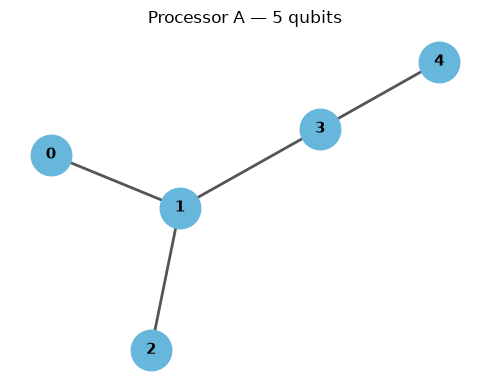

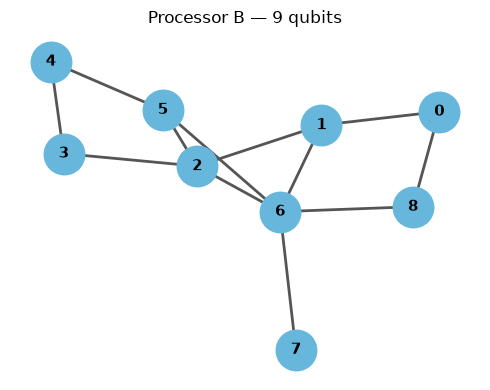

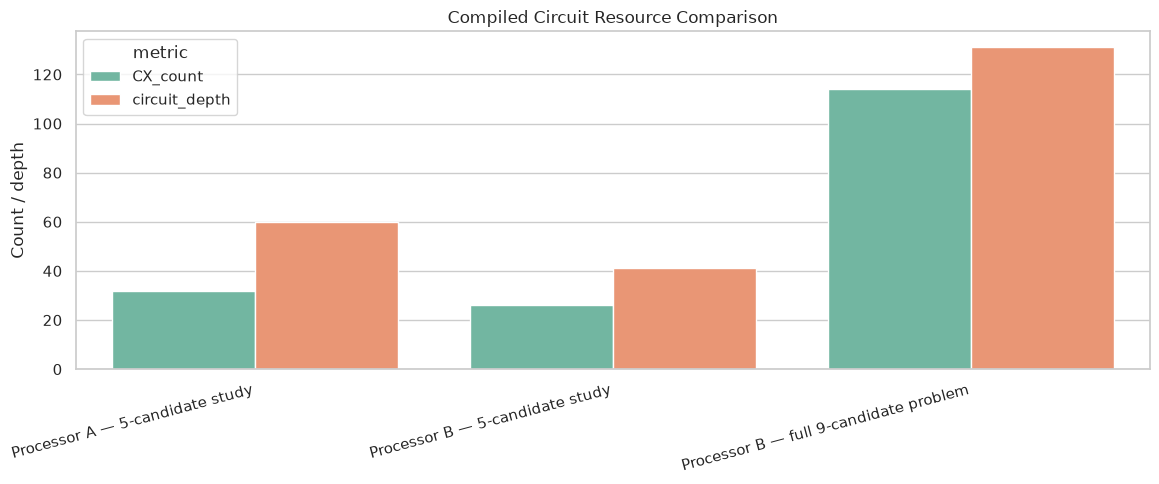

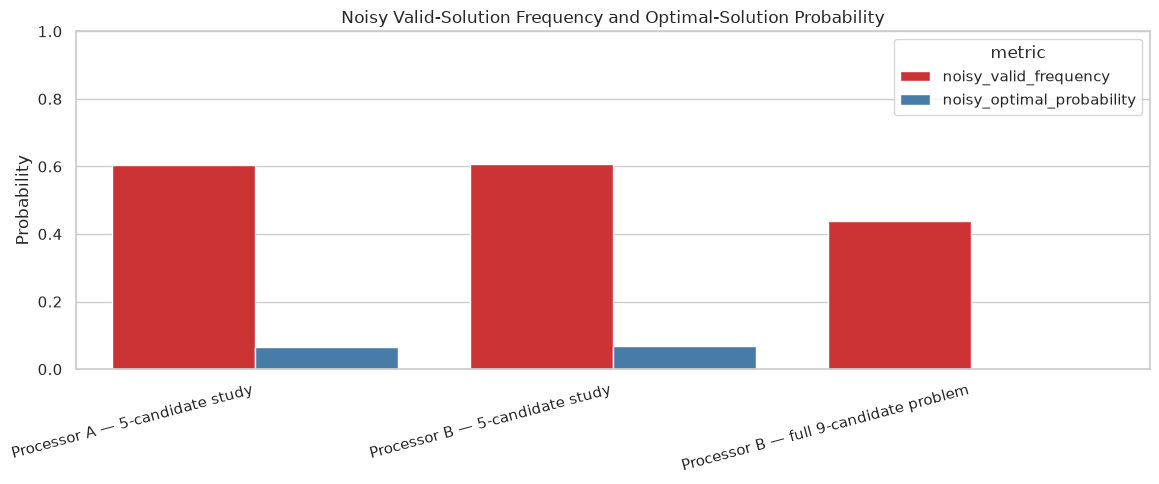

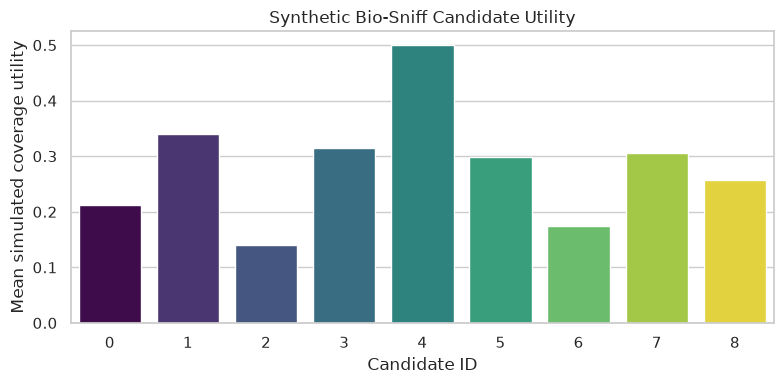


Benchmark computation and plots complete.

================ MULTI-START VARIABILITY ================


,problem,count,mean,std,min,max
0,Five-candidate,5,-24.852604,1.072025,-26.500699,-23.636707
1,Nine-candidate,5,-19.572663,4.348016,-25.558002,-14.933177


In [3]:
# ============================================================
# 1. HELPER FUNCTIONS FOR CLASSICAL REFERENCE AND SIMULATION
# ============================================================

def exact_classical_solution(utility, complementarity, spacing, k=K_SELECTED):
    n = len(utility)
    best_score = -np.inf
    best_selection = None

    # Exhaustively test every valid exactly-k combination.
    for selection in itertools.combinations(range(n), k):
        score = placement_reward(
            selection, utility, complementarity, spacing
        )
        if score > best_score:
            best_score = score
            best_selection = tuple(selection)

    return best_selection, float(best_score)


def sample_statistics(counts, utility, complementarity, spacing,
                      exact_selection, candidate_ids, k=K_SELECTED):
    total_shots = sum(counts.values())
    valid_shots = 0
    optimal_shots = 0
    best_score = None
    best_selection = None

    for bitstring, count in counts.items():
        bits = [int(c) for c in bitstring.replace(" ", "")[::-1]]
        selected = tuple(i for i, bit in enumerate(bits) if bit == 1)

        if len(selected) != k:
            continue

        valid_shots += count

        if tuple(sorted(selected)) == tuple(sorted(exact_selection)):
            optimal_shots += count

        score = placement_reward(
            selected, utility, complementarity, spacing
        )

        if best_score is None or score > best_score:
            best_score = score
            best_selection = selected

    return {
        "valid_frequency": valid_shots / total_shots,
        "optimal_probability": optimal_shots / total_shots,
        "best_sampled_reward": (
            best_score if best_score is not None else np.nan
        ),
        "best_sampled_candidates": (
            [candidate_ids[i] for i in best_selection]
            if best_selection is not None else None
        )
    }



from qiskit.transpiler import CouplingMap

def run_architecture(
    label, Q, params, coupling_map,
    utility, complementarity, spacing,
    candidate_ids, physical_qubits, shots=SHOTS
):
    n = len(utility)

    exact_selection, exact_score = exact_classical_solution(
        utility, complementarity, spacing
    )

    logical = qaoa_circuit(
        Q, params[0], params[1], measure=True
    )

    # Convert the edge list into a proper Qiskit CouplingMap.
    hardware_map = CouplingMap(couplinglist=coupling_map)
    hardware_map.make_symmetric()

    start = time.perf_counter()

    compiled = transpile(
        logical,
        basis_gates=BASIS_GATES,
        coupling_map=hardware_map,
        optimization_level=1,
        seed_transpiler=SEED
    )

    compile_seconds = time.perf_counter() - start
    operations = compiled.count_ops()

    # Fully connected reference with the SAME logical width.
    complete_edges = [
        (i, j)
        for i in range(n)
        for j in range(n)
        if i != j
    ]
    complete_map = CouplingMap(couplinglist=complete_edges)
    complete_map.make_symmetric()

    fully_connected_circuit = transpile(
        logical,
        basis_gates=BASIS_GATES,
        coupling_map=complete_map,
        optimization_level=1,
        seed_transpiler=SEED
    )

    compiled_cx = int(operations.get("cx", 0))
    baseline_cx = int(
        fully_connected_circuit.count_ops().get("cx", 0)
    )
    routing_cx_proxy = max(0, compiled_cx - baseline_cx)

    # Ideal sampled simulation.
    ideal_backend = AerSimulator()
    ideal_counts = ideal_backend.run(
        compiled, shots=shots, seed_simulator=SEED
    ).result().get_counts()

    ideal_stats = sample_statistics(
        ideal_counts, utility, complementarity, spacing,
        exact_selection, candidate_ids
    )

    # Noisy sampled simulation.
    noisy_backend = AerSimulator(noise_model=make_noise_model())
    noisy_counts = noisy_backend.run(
        compiled, shots=shots, seed_simulator=SEED
    ).result().get_counts()

    noisy_stats = sample_statistics(
        noisy_counts, utility, complementarity, spacing,
        exact_selection, candidate_ids
    )

    return {
        "processor": label,
        "logical_qubits": n,
        "physical_qubits_in_compiled_circuit": compiled.num_qubits,
        "coupling_edges": len(hardware_map.get_edges()) // 2,
        "classical_optimum_reward": exact_score,
        "classical_optimum_candidates": [
            candidate_ids[i] for i in exact_selection
        ],
        "ideal_best_reward": ideal_stats["best_sampled_reward"],
        "ideal_valid_frequency": ideal_stats["valid_frequency"],
        "ideal_optimal_probability": ideal_stats["optimal_probability"],
        "noisy_best_reward": noisy_stats["best_sampled_reward"],
        "noisy_valid_frequency": noisy_stats["valid_frequency"],
        "noisy_optimal_probability": noisy_stats["optimal_probability"],
        "noisy_best_candidates": noisy_stats["best_sampled_candidates"],
        "CX_count": compiled_cx,
        "CX_all_to_all_reference": baseline_cx,
        "routing_CX_overhead_proxy": routing_cx_proxy,
        "explicit_SWAP_count": int(operations.get("swap", 0)),
        "circuit_depth": compiled.depth(),
        "single_qubit_gate_count": sum(
            count for gate, count in operations.items()
            if gate in ["rz", "sx", "x"]
        ),
        "transpilation_seconds": compile_seconds,
        "shots": shots
    }


# ============================================================
# 2. CREATE THE FIVE-CANDIDATE COMMON COMPARISON
#
# Both A and B solve the SAME five-candidate, choose-three
# subproblem. This makes the connectivity comparison fair.
# ============================================================

COMMON_IDS = list(range(5))

U5 = UTILITY[:5]
C5 = COMPLEMENTARITY[:5, :5]
S5 = SPACING[:5, :5]

Q5 = build_qubo(U5, C5, S5, k=K_SELECTED)

print("Optimizing common five-candidate QAOA instance with 5 initializations...")
params5, optimizer5, multistart_5 = multi_start_optimize_qaoa(Q5)

print("Selected five-candidate parameters:", np.round(params5, 5))
print("Best expected QUBO energy:", optimizer5.fun)
print("Five-candidate initialization summary:")
display(multistart_5)

# Processor A: 5 physical qubits.
result_A = run_architecture(
    "Processor A — 5-candidate study",
    Q5, params5, COUPLING_A,
    U5, C5, S5, COMMON_IDS,
    physical_qubits=5
)

# Processor B: same five-candidate logical problem,
# mapped to the nine-qubit Processor B graph.
result_B_5 = run_architecture(
    "Processor B — 5-candidate study",
    Q5, params5, COUPLING_B,
    U5, C5, S5, COMMON_IDS,
    physical_qubits=9
)


# ============================================================
# 3. FULL BIOSNIFF INSTANCE: NINE CANDIDATES ON PROCESSOR B
# Processor A cannot directly host this nine-qubit encoding.
# ============================================================

Q9 = build_qubo(
    UTILITY, COMPLEMENTARITY, SPACING, k=K_SELECTED
)

print("\nOptimizing full nine-candidate QAOA instance with 5 initializations...")
params9, optimizer9, multistart_9 = multi_start_optimize_qaoa(Q9)

print("Selected nine-candidate parameters:", np.round(params9, 5))
print("Best expected QUBO energy:", optimizer9.fun)
print("Nine-candidate initialization summary:")
display(multistart_9)

result_B_9 = run_architecture(
    "Processor B — full 9-candidate problem",
    Q9, params9, COUPLING_B,
    UTILITY, COMPLEMENTARITY, SPACING,
    list(range(9)),
    physical_qubits=9
)


# ============================================================
# 4. PRINT RESULTS TABLE
# ============================================================

results = pd.DataFrame([result_A, result_B_5, result_B_9])

columns_to_show = [
    "processor",
    "logical_qubits",
    "physical_qubits_in_compiled_circuit",
    "classical_optimum_reward",
    "ideal_best_reward",
    "noisy_best_reward",
    "noisy_valid_frequency",
    "noisy_optimal_probability",
    "CX_count",
    "routing_CX_overhead_proxy",
    "explicit_SWAP_count",
    "circuit_depth",
    "transpilation_seconds"
]

print("\n================ BENCHMARK RESULTS ================")
display(results[columns_to_show].round(4))

print("\n================ SELECTED CANDIDATES ================")
for _, row in results.iterrows():
    print(f"\n{row['processor']}")
    print("Exact classical optimum:", row["classical_optimum_candidates"])
    print("Best noisy sampled selection:", row["noisy_best_candidates"])


# ============================================================
# 5. VISUALIZE THE TWO COUPLING MAPS
# ============================================================

def plot_processor_graph(title, n, edges):
    graph = nx.Graph()
    graph.add_nodes_from(range(n))
    graph.add_edges_from(edges)

    pos = nx.spring_layout(graph, seed=SEED)

    plt.figure(figsize=(5, 4))
    nx.draw_networkx(
        graph, pos,
        node_color="#67b7dc",
        node_size=850,
        font_size=11,
        font_weight="bold",
        edge_color="#555555",
        width=2
    )
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_processor_graph(
    "Processor A — 5 qubits",
    5, PROCESSOR_A_EDGES
)

plot_processor_graph(
    "Processor B — 9 qubits",
    9, PROCESSOR_B_EDGES
)


# ============================================================
# 6. COLORFUL COMPARISON GRAPHS
# ============================================================

sns.set_theme(style="whitegrid", context="notebook")

# Resource comparison. The B full-instance row uses 9 logical
# qubits, so interpret it separately from the five-qubit study.
resource_df = results.melt(
    id_vars="processor",
    value_vars=["CX_count", "circuit_depth"],
    var_name="metric",
    value_name="value"
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=resource_df,
    x="processor",
    y="value",
    hue="metric",
    palette="Set2"
)
plt.title("Compiled Circuit Resource Comparison")
plt.ylabel("Count / depth")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# Noisy solution-quality comparison.
quality_df = results.melt(
    id_vars="processor",
    value_vars=[
        "noisy_valid_frequency",
        "noisy_optimal_probability"
    ],
    var_name="metric",
    value_name="probability"
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=quality_df,
    x="processor",
    y="probability",
    hue="metric",
    palette="Set1"
)
plt.title("Noisy Valid-Solution Frequency and Optimal-Solution Probability")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


# Compare candidate utility used by the synthetic test instance.
plt.figure(figsize=(8, 4))
sns.barplot(
    x=np.arange(9),
    y=UTILITY,
    hue=np.arange(9),
    palette="viridis",
    legend=False
)
plt.title("Synthetic Bio-Sniff Candidate Utility")
plt.xlabel("Candidate ID")
plt.ylabel("Mean simulated coverage utility")
plt.tight_layout()
plt.show()

print('\nBenchmark computation and plots complete.')

# Compare variability across optimizer starting points.
multistart_summary = pd.concat([
    multistart_5.assign(problem="Five-candidate"),
    multistart_9.assign(problem="Nine-candidate")
], ignore_index=True)

print("\n================ MULTI-START VARIABILITY ================")
display(
    multistart_summary.groupby("problem")["expected_qubo_energy"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)



Processor A — transpiled QAOA circuit
Logical circuit width: 5
Compiled circuit width: 5
Operations: OrderedDict({'rz': 35, 'cx': 32, 'sx': 15, 'measure': 5, 'barrier': 1})


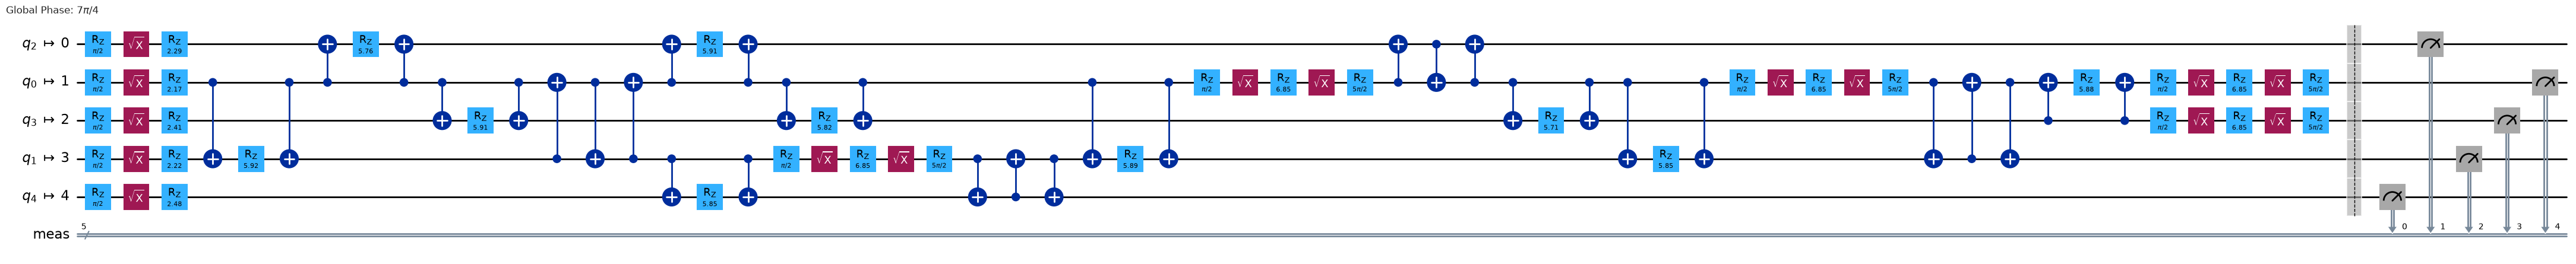

Processor B — transpiled QAOA circuit (same five-candidate problem)
Logical circuit width: 5
Compiled circuit width: 9
Operations: OrderedDict({'rz': 35, 'cx': 26, 'sx': 15, 'measure': 5, 'barrier': 1})


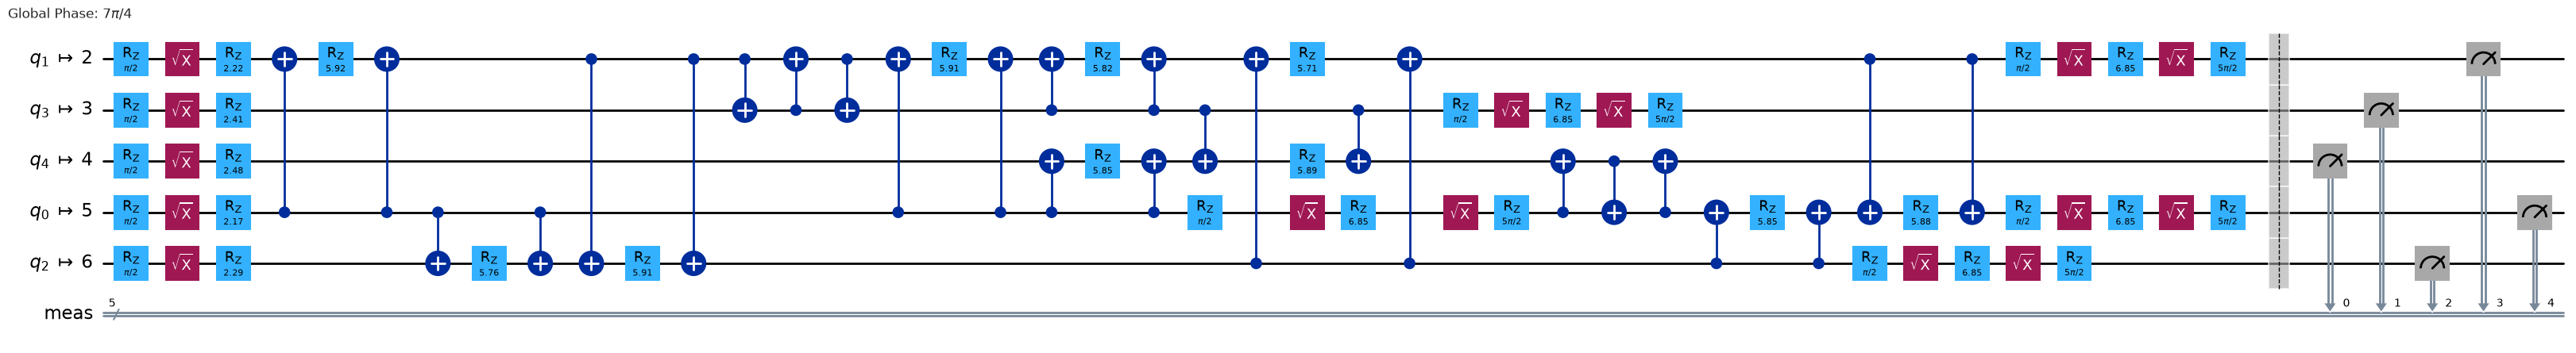


Circuit diagrams saved:
/content/results/images/processor_a_qaoa_circuit.png
/content/results/images/processor_b_qaoa_circuit.png
Copy these PNG files into your repository at results/images/.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ============================================================
# VISUALIZE AND EXPORT PROCESSOR A / PROCESSOR B QAOA CIRCUITS
# ============================================================
# Fair comparison: use the SAME five-candidate logical QAOA circuit
# and the same optimized parameters, then transpile it to each topology.
# These are simulated connectivity configurations, not physical devices.

from pathlib import Path
from IPython.display import display
from qiskit.transpiler import CouplingMap
import matplotlib.pyplot as plt

circuit_output_dir = Path("/content/results/images")
circuit_output_dir.mkdir(parents=True, exist_ok=True)

# Build one logical QAOA circuit from the five-candidate problem.
logical_qaoa_5 = qaoa_circuit(
    Q5, params5[0], params5[1], measure=True
)

# Processor A: 5-qubit coupling map.
map_a = CouplingMap(couplinglist=COUPLING_A)
map_a.make_symmetric()
qaoa_processor_a = transpile(
    logical_qaoa_5,
    basis_gates=BASIS_GATES,
    coupling_map=map_a,
    optimization_level=1,
    seed_transpiler=SEED
)

# Processor B: 9-qubit coupling map, using the same 5-qubit logical problem.
map_b = CouplingMap(couplinglist=COUPLING_B)
map_b.make_symmetric()
qaoa_processor_b = transpile(
    logical_qaoa_5,
    basis_gates=BASIS_GATES,
    coupling_map=map_b,
    optimization_level=1,
    seed_transpiler=SEED
)

print("Processor A — transpiled QAOA circuit")
print("Logical circuit width:", logical_qaoa_5.num_qubits)
print("Compiled circuit width:", qaoa_processor_a.num_qubits)
print("Operations:", qaoa_processor_a.count_ops())
fig_a = qaoa_processor_a.draw(output="mpl", fold=100, idle_wires=False)
display(fig_a)
path_a = circuit_output_dir / "processor_a_qaoa_circuit.png"
fig_a.savefig(path_a, dpi=200, bbox_inches="tight")
plt.close(fig_a)

print("Processor B — transpiled QAOA circuit (same five-candidate problem)")
print("Logical circuit width:", logical_qaoa_5.num_qubits)
print("Compiled circuit width:", qaoa_processor_b.num_qubits)
print("Operations:", qaoa_processor_b.count_ops())
fig_b = qaoa_processor_b.draw(output="mpl", fold=100, idle_wires=False)
display(fig_b)
path_b = circuit_output_dir / "processor_b_qaoa_circuit.png"
fig_b.savefig(path_b, dpi=200, bbox_inches="tight")
plt.close(fig_b)

print("\nCircuit diagrams saved:")
print(path_a)
print(path_b)
print("Copy these PNG files into your repository at results/images/.")

# Download both images from Colab.
from google.colab import files
files.download(str(path_a))
files.download(str(path_b))


In [7]:

from pathlib import Path
import ast
import pandas as pd
from google.colab import files

# 1. Validate that benchmark results exist
assert "results" in globals(), (
    "Benchmark results are missing. Run the benchmark cell first."
)
assert isinstance(results, pd.DataFrame) and not results.empty, (
    "`results` must be a non-empty DataFrame from the current run."
)
assert "multistart_summary" in globals(), (
    "Multi-start results are missing. Run the multi-start benchmark first."
)
assert isinstance(multistart_summary, pd.DataFrame) and not multistart_summary.empty, (
    "`multistart_summary` must be a non-empty DataFrame."
)

# 2. Define output files
output_dir = Path("/content")
csv_path = output_dir / "biosniff_processor_A_B_results.csv"
config_path = output_dir / "biosniff_benchmark_config.txt"
multistart_path = output_dir / "biosniff_optimizer_multistart.csv"

# 3. Export computed results
results.to_csv(csv_path, index=False)
multistart_summary.to_csv(multistart_path, index=False)

# 4. Generate configuration from the current run
config_text = f"""Bio-Sniff QAOA Synthetic Architecture Benchmark
================================================

Data status:
Synthetic placement scenarios and scores; not physical field measurements.

Problem:
Select exactly {K_SELECTED} locations from {len(UTILITY)} candidate locations.

Objective weights:
Utility = 0.60
Complementarity = 0.25
Spatial distribution = 0.15

QAOA:
p = {QAOA_P}
Shots = {SHOTS}
Random seed = {SEED}
Optimizer = COBYLA
Maximum iterations per optimization = {MAXITER}
Penalty = {PENALTY}

Noise assumptions:
Single-qubit depolarizing probability = {P_1Q}
CX depolarizing probability = {P_CX}
Readout bit-flip probability = {P_READOUT}

Transpilation:
Optimization level = 1
Basis gates = {", ".join(BASIS_GATES)}
Transpiler random seed = {SEED}

Processor A edges:
{PROCESSOR_A_EDGES}

Processor B edges:
{PROCESSOR_B_EDGES}

Results generated in this run:
{results[["processor", "classical_optimum_reward", "noisy_valid_frequency", "noisy_optimal_probability", "noisy_best_candidates"]].to_string(index=False)}

Multi-start initialization summary:
{multistart_summary.to_string(index=False)}

Limitations:
Synthetic placement inputs; no real-field validation or quantum advantage claimed.
"""

config_path.write_text(config_text, encoding="utf-8")

# 5. Read back the benchmark CSV
saved_results = pd.read_csv(csv_path)

assert list(saved_results.columns) == list(results.columns), (
    "Saved CSV columns do not match computed results."
)
assert len(saved_results) == len(results), (
    "Saved CSV row count does not match computed results."
)

# CSV stores Python lists as strings; convert them back before comparing.
for col in results.columns:
    if len(results) > 0 and isinstance(results[col].iloc[0], list):
        saved_results[col] = saved_results[col].apply(
            lambda value: ast.literal_eval(value)
            if isinstance(value, str) else value
        )

# 6. Compare saved and computed results
pd.testing.assert_frame_equal(
    results.reset_index(drop=True),
    saved_results.reset_index(drop=True),
    check_dtype=False,
    check_exact=False,
    rtol=1e-8,
    atol=1e-10
)

# 7. Verify all artifacts exist and are non-empty
for path in (csv_path, config_path, multistart_path):
    assert path.exists() and path.stat().st_size > 0, (
        f"Output file is missing or empty: {path.name}"
    )

print("SUCCESS: CSV matches the computed benchmark DataFrame.")
print("Benchmark CSV:", csv_path)
print("Configuration:", config_path)
print("Multi-start summary:", multistart_path)

display(saved_results)
display(multistart_summary)

# 8. Download all three artifacts
files.download(str(csv_path))
files.download(str(config_path))
files.download(str(multistart_path))


SUCCESS: CSV matches the computed benchmark DataFrame.
Benchmark CSV: /content/biosniff_processor_A_B_results.csv
Configuration: /content/biosniff_benchmark_config.txt
Multi-start summary: /content/biosniff_optimizer_multistart.csv


,processor,logical_qubits,physical_qubits_in_compiled_circuit,coupling_edges,classical_optimum_reward,classical_optimum_candidates,ideal_best_reward,ideal_valid_frequency,ideal_optimal_probability,noisy_best_reward,...,noisy_optimal_probability,noisy_best_candidates,CX_count,CX_all_to_all_reference,routing_CX_overhead_proxy,explicit_SWAP_count,circuit_depth,single_qubit_gate_count,transpilation_seconds,shots
0,Processor A — 5-candidate study,5,5,4,1.165737,"[2, 3, 4]",1.165737,0.658203,0.071289,1.165737,...,0.065186,"[2, 3, 4]",32,20,12,0,60,50,0.106634,4096
1,Processor B — 5-candidate study,5,9,12,1.165737,"[2, 3, 4]",1.165737,0.657959,0.077881,1.165737,...,0.067139,"[2, 3, 4]",26,20,6,0,41,50,0.008468,4096
2,Processor B — full 9-candidate problem,9,9,12,1.452471,"[1, 6, 8]",1.452471,0.544678,0.005371,1.452471,...,0.004150,"[1, 6, 8]",114,72,42,0,131,108,0.011975,4096


,seed,expected_qubo_energy,optimizer_success,iterations,termination_message,problem
0,42,-25.046791,True,39,Return from COBYLA because the trust region ra...,Five-candidate
1,43,-23.636707,True,32,Return from COBYLA because the trust region ra...,Five-candidate
2,44,-24.249208,True,36,Return from COBYLA because the trust region ra...,Five-candidate
3,45,-26.500699,True,30,Return from COBYLA because the trust region ra...,Five-candidate
4,46,-24.829615,True,32,Return from COBYLA because the trust region ra...,Five-candidate
5,42,-25.558002,True,31,Return from COBYLA because the trust region ra...,Nine-candidate
6,43,-18.861164,True,26,Return from COBYLA because the trust region ra...,Nine-candidate
7,44,-14.933177,False,60,Return from COBYLA because the objective funct...,Nine-candidate
8,45,-16.292008,True,26,Return from COBYLA because the trust region ra...,Nine-candidate
9,46,-22.218965,True,28,Return from COBYLA because the trust region ra...,Nine-candidate


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from pathlib import Path
import pandas as pd

csv_path = Path("/content/biosniff_processor_A_B_results.csv")
config_path = Path("/content/biosniff_benchmark_config.txt")

for path in (csv_path, config_path):
    print(f"{path.name}: {'EXISTS' if path.exists() else 'MISSING'}")
    assert path.exists(), f"Missing expected artifact: {path}"

checked = pd.read_csv(csv_path)
assert len(checked) == 3, f"Expected 3 benchmark rows; found {len(checked)}"
assert "classical_optimum_reward" in checked.columns
assert "noisy_optimal_probability" in checked.columns

print("Artifact checks passed.")


biosniff_processor_A_B_results.csv: EXISTS
biosniff_benchmark_config.txt: EXISTS
Artifact checks passed.
